# Exercise 11: Decision Tree (Solution)
### (010000) Machine Learning - Spring 2026
### Prof. Cheol Jeong, Sejong University

## Tasks 1 & 2: Load the Wine Dataset with 'entropy' Criterion

We use the Wine dataset with the `'entropy'` criterion (Information Gain).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

wine = load_wine(as_frame=True)
X = wine.data.copy()
y = wine.target.copy()
class_names = list(wine.target_names)
label_to_name = {i: name for i, name in enumerate(class_names)}

print("Feature names:", wine.feature_names)
print("Class names:", class_names)
print("Input shape:", X.shape)

Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Class names: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
Input shape: (178, 13)


## Train/Test Split

Split the data with `test_size=0.3`, `random_state=2026`, and `stratify=y` to preserve class proportions.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2026, stratify=y
)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (124, 13)
X_test shape: (54, 13)


## Task 3: Train with max_depth=4 and criterion='entropy'

Train a Decision Tree classifier with `max_depth=4` and `criterion='entropy'`, then report the confusion matrix, classification report, and feature importances.

In [3]:
clf = DecisionTreeClassifier(max_depth=4, criterion='entropy', random_state=2026)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

### Confusion Matrix

                Predicted class_0  Predicted class_1  Predicted class_2
Actual class_0                 17                  1                  0
Actual class_1                  3                 14                  4
Actual class_2                  0                  2                 13


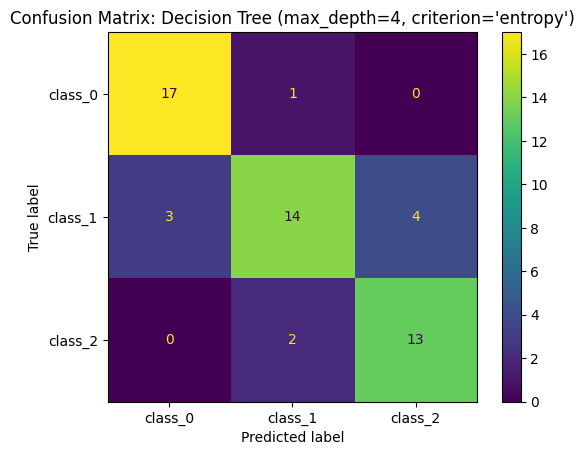

In [4]:
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm,
    index=[f"Actual {n}" for n in class_names],
    columns=[f"Predicted {n}" for n in class_names])
print(cm_df)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot()
plt.title("Confusion Matrix: Decision Tree (max_depth=4, criterion='entropy')")
plt.show()

### Classification Report

In [5]:
report = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)
report_df = pd.DataFrame(report).transpose()
print(report_df)

              precision    recall  f1-score    support
class_0        0.850000  0.944444  0.894737  18.000000
class_1        0.823529  0.666667  0.736842  21.000000
class_2        0.764706  0.866667  0.812500  15.000000
accuracy       0.814815  0.814815  0.814815   0.814815
macro avg      0.812745  0.825926  0.814693  54.000000
weighted avg   0.816013  0.814815  0.810490  54.000000


### Feature Importances

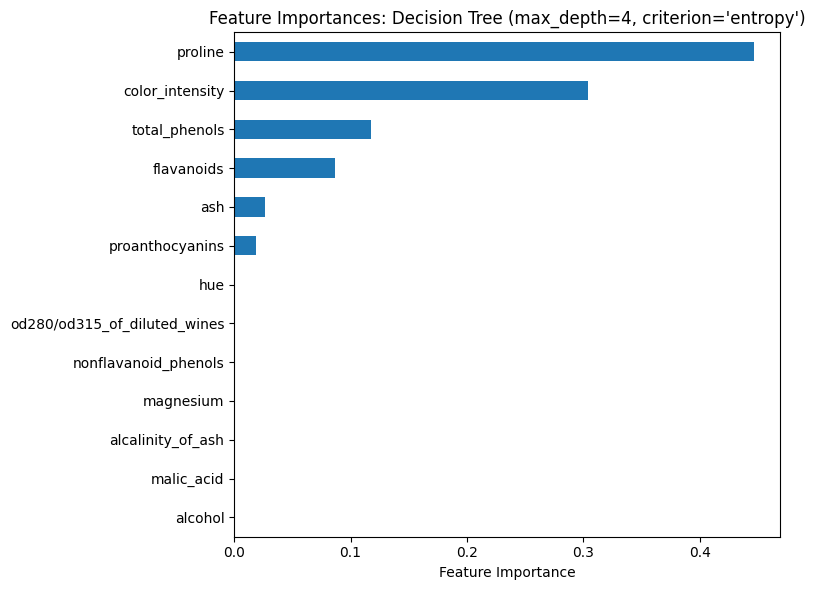

In [6]:
importances = pd.Series(clf.feature_importances_, index=wine.feature_names)
importances_sorted = importances.sort_values(ascending=True)

plt.figure(figsize=(8, 6))
importances_sorted.plot(kind='barh')
plt.xlabel("Feature Importance")
plt.title("Feature Importances: Decision Tree (max_depth=4, criterion='entropy')")
plt.tight_layout()
plt.show()